In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_curve, average_precision_score,
    roc_auc_score, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
print('All imports OK')

All imports OK


In [9]:
CSV_PATH = 'PS_20174392719_1491204439457_log.csv'   # <-- update if needed

df = pd.read_csv(CSV_PATH)
print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}')
df.head()

Rows: 818,487  |  Columns: 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


In [ ]:
print('Data Types')
print(df.dtypes)
print()
print('Missing Values')
print(df.isnull().sum())

=== Data Types ===
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud           float64
isFlaggedFraud    float64
dtype: object

=== Missing Values ===
step              0
type              1
amount            1
nameOrig          1
oldbalanceOrg     1
newbalanceOrig    1
nameDest          1
oldbalanceDest    1
newbalanceDest    1
isFraud           1
isFlaggedFraud    1
dtype: int64


Legit transactions :    818,018
Fraud transactions :        468
Fraud rate         : 0.0572%


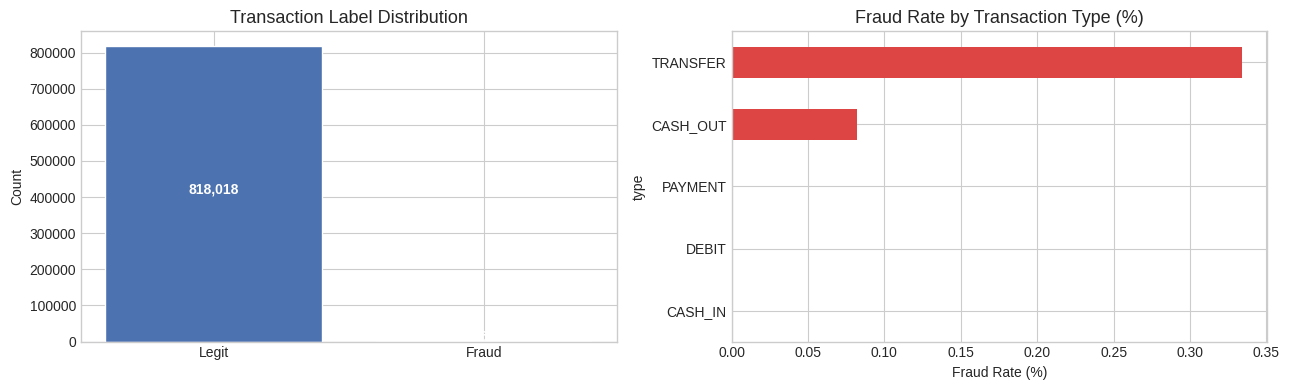


Fraud only happens in:
type
CASH_OUT    242
TRANSFER    226
Name: count, dtype: int64


In [11]:
fraud_count = df['isFraud'].value_counts()
fraud_pct   = df['isFraud'].mean() * 100

print(f"Legit transactions : {fraud_count[0]:>10,}")
print(f"Fraud transactions : {fraud_count[1]:>10,}")
print(f"Fraud rate         : {fraud_pct:.4f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Class bar
axes[0].bar(['Legit', 'Fraud'], fraud_count.values,
            color=['#4C72B0', '#DD4444'], edgecolor='white')
axes[0].set_title('Transaction Label Distribution', fontsize=13)
axes[0].set_ylabel('Count')
for bar, val in zip(axes[0].patches, fraud_count.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() * 0.5, f'{val:,}',
                 ha='center', color='white', fontweight='bold')

# Transaction type breakdown
type_fraud = df.groupby('type')['isFraud'].agg(['sum','count'])
type_fraud['fraud_rate'] = type_fraud['sum'] / type_fraud['count'] * 100
type_fraud['fraud_rate'].sort_values().plot(kind='barh', ax=axes[1],
                                             color='#DD4444')
axes[1].set_title('Fraud Rate by Transaction Type (%)', fontsize=13)
axes[1].set_xlabel('Fraud Rate (%)')
plt.tight_layout()
plt.show()

print('\nFraud only happens in:')
print(df[df['isFraud']==1]['type'].value_counts())

=== Origin account newbalance after transaction ===
Fraud  — median newbalanceOrig : 0.00
Legit  — median newbalanceOrig : 0.00


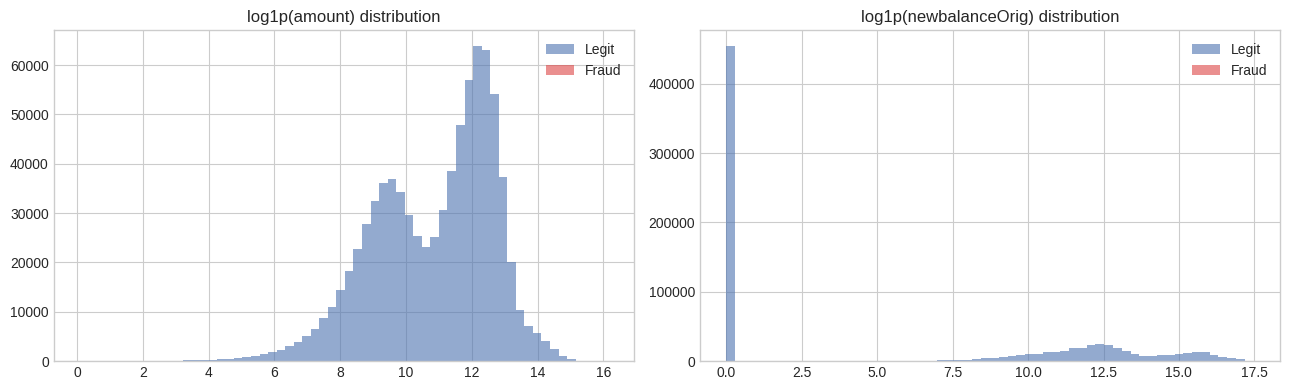

In [12]:
fraud_df = df[df['isFraud'] == 1]
legit_df = df[df['isFraud'] == 0]

print('=== Origin account newbalance after transaction ===')
print(f"Fraud  — median newbalanceOrig : {fraud_df['newbalanceOrig'].median():,.2f}")
print(f"Legit  — median newbalanceOrig : {legit_df['newbalanceOrig'].median():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['amount', 'newbalanceOrig']):
    ax.hist(np.log1p(legit_df[col]), bins=60, alpha=0.6,
            label='Legit', color='#4C72B0')
    ax.hist(np.log1p(fraud_df[col]), bins=60, alpha=0.6,
            label='Fraud', color='#DD4444')
    ax.set_title(f'log1p({col}) distribution', fontsize=12)
    ax.legend()
plt.tight_layout()
plt.show()

In [13]:
def engineer_features(df):
    df = df.copy()

    # 1. Encode transaction type
    le = LabelEncoder()
    df['type_enc'] = le.fit_transform(df['type'])

    # 2. Balance error features — how much the books don't add up
    #    For origin: expected new balance = old - amount
    df['errorOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
    #    For dest: expected new balance = old + amount
    df['errorDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']

    # 3. Account drained to 0 (hallmark of fraud)
    df['orig_zero_after'] = (df['newbalanceOrig'] == 0).astype(int)
    df['dest_zero_before'] = (df['oldbalanceDest'] == 0).astype(int)

    # 4. Amount ratio relative to source balance
    df['amount_ratio_orig'] = np.where(
    df['oldbalanceOrg'] + 1 > 0,
    df['amount'] / (df['oldbalanceOrg'] + 1),
    0
)

    # 5. Is the transaction type one where fraud occurs?
    df['is_high_risk_type'] = df['type'].isin(['TRANSFER', 'CASH_OUT']).astype(int)

    # 6. Destination balance unchanged despite receiving money
    df['dest_balance_unchanged'] = (
        (df['newbalanceDest'] == df['oldbalanceDest']) &
        (df['amount'] > 0)
    ).astype(int)

    return df


df = engineer_features(df)

# Drop columns not useful for modelling
DROP_COLS = ['nameOrig', 'nameDest', 'type', 'isFlaggedFraud']
FEATURE_COLS = [c for c in df.columns if c not in DROP_COLS + ['isFraud']]

print('Features used for training:')
print(FEATURE_COLS)

Features used for training:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_enc', 'errorOrig', 'errorDest', 'orig_zero_after', 'dest_zero_before', 'amount_ratio_orig', 'is_high_risk_type', 'dest_balance_unchanged']


In [ ]:
#  Clean up before splitting 

df.dropna(subset=['isFraud'], inplace=True)

# Also fill any NaN in feature columns (from edge-case divisions)
df[FEATURE_COLS] = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
df[FEATURE_COLS] = df[FEATURE_COLS].fillna(0)

X = df[FEATURE_COLS]
y = df['isFraud'].astype(int)   # <-- ensure int, not float/object

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

In [15]:
X = df[FEATURE_COLS]
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f'Train: {len(X_train):,} rows   |   Test: {len(X_test):,} rows')
print(f'Train fraud rate: {y_train.mean()*100:.4f}%')
print(f'Test  fraud rate: {y_test.mean()*100:.4f}%')

Train: 654,788 rows   |   Test: 163,698 rows
Train fraud rate: 0.0571%
Test  fraud rate: 0.0574%


In [16]:
def evaluate(name, model, X_test, y_test, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    preds = (proba >= threshold).astype(int)

    print(f'\n{'='*55}')
    print(f'  {name}')
    print(f'{'='*55}')
    print(classification_report(y_test, preds,
                                 target_names=['Legit', 'Fraud']))
    print(f'ROC-AUC  : {roc_auc_score(y_test, proba):.4f}')
    print(f'PR-AUC   : {average_precision_score(y_test, proba):.4f}')

    # Confusion matrix
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, preds),
        display_labels=['Legit', 'Fraud']
    ).plot(ax=axes[0], colorbar=False, cmap='Blues')
    axes[0].set_title(f'{name} — Confusion Matrix')

    # Precision-Recall curve
    prec, rec, threshs = precision_recall_curve(y_test, proba)
    pr_auc = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, color='#DD4444', lw=2,
                 label=f'PR-AUC = {pr_auc:.4f}')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title(f'{name} — Precision-Recall Curve')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    return proba

Training Random Forest...
Done!

  Random Forest
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00    163604
       Fraud       1.00      0.90      0.95        94

    accuracy                           1.00    163698
   macro avg       1.00      0.95      0.97    163698
weighted avg       1.00      1.00      1.00    163698

ROC-AUC  : 0.9627
PR-AUC   : 0.9256


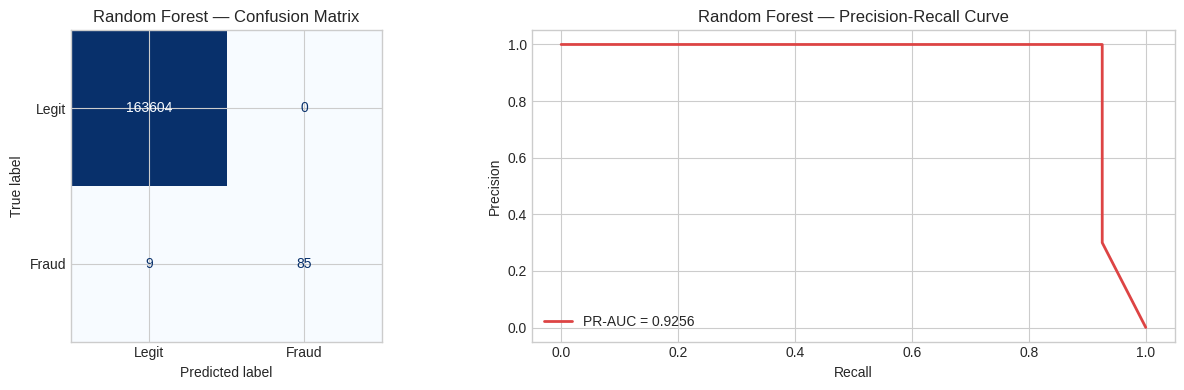

In [17]:
print('Training Random Forest...')
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight='balanced',   # handles imbalance
    random_state=SEED,
    n_jobs=-1
)
rf.fit(X_train, y_train)
print('Done!')

rf_proba = evaluate('Random Forest', rf, X_test, y_test)

scale_pos_weight = 1749.8
[0]	validation_0-aucpr:0.93458
[50]	validation_0-aucpr:0.92304
[100]	validation_0-aucpr:0.91936
[150]	validation_0-aucpr:0.91849
[200]	validation_0-aucpr:0.91798
[250]	validation_0-aucpr:0.91782
[299]	validation_0-aucpr:0.91857

  XGBoost
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00    163604
       Fraud       0.96      0.91      0.93        94

    accuracy                           1.00    163698
   macro avg       0.98      0.96      0.97    163698
weighted avg       1.00      1.00      1.00    163698

ROC-AUC  : 0.9677
PR-AUC   : 0.9186


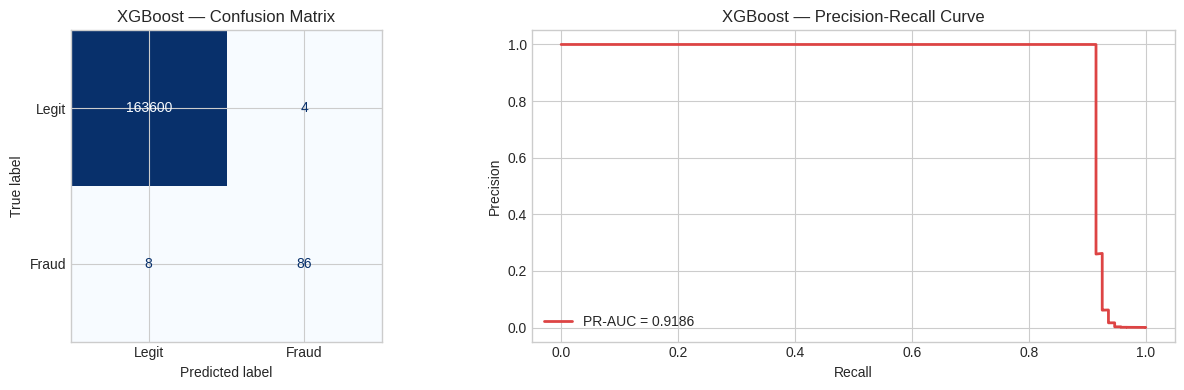

In [18]:
neg  = (y_train == 0).sum()
pos  = (y_train == 1).sum()
spw  = neg / pos
print(f'scale_pos_weight = {spw:.1f}')

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=spw,
    tree_method='hist',        # fast, works on CPU & GPU
    eval_metric='aucpr',
    random_state=SEED,
    n_jobs=-1
)
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

xgb_proba = evaluate('XGBoost', xgb, X_test, y_test)

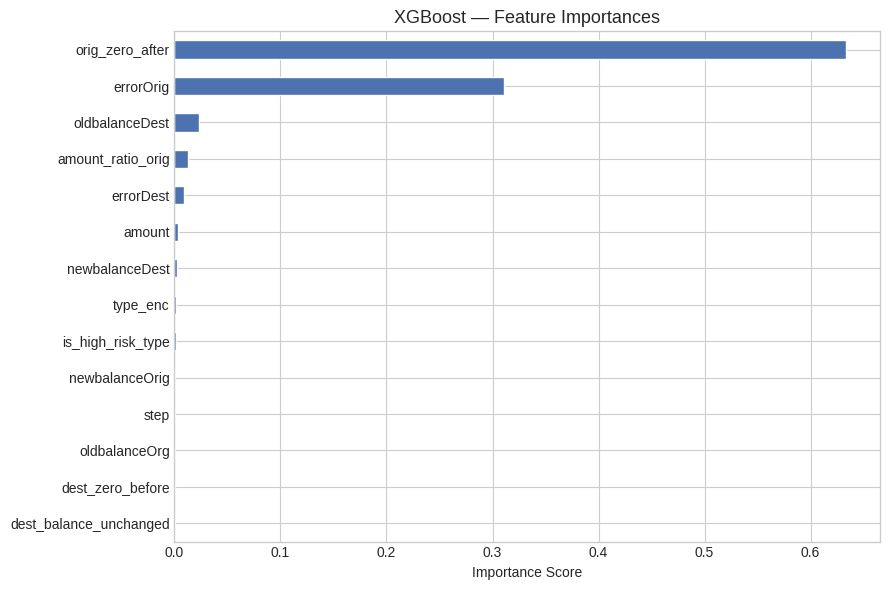

In [19]:
imp = pd.Series(xgb.feature_importances_, index=FEATURE_COLS)
imp = imp.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
imp.plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='white')
ax.set_title('XGBoost — Feature Importances', fontsize=13)
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

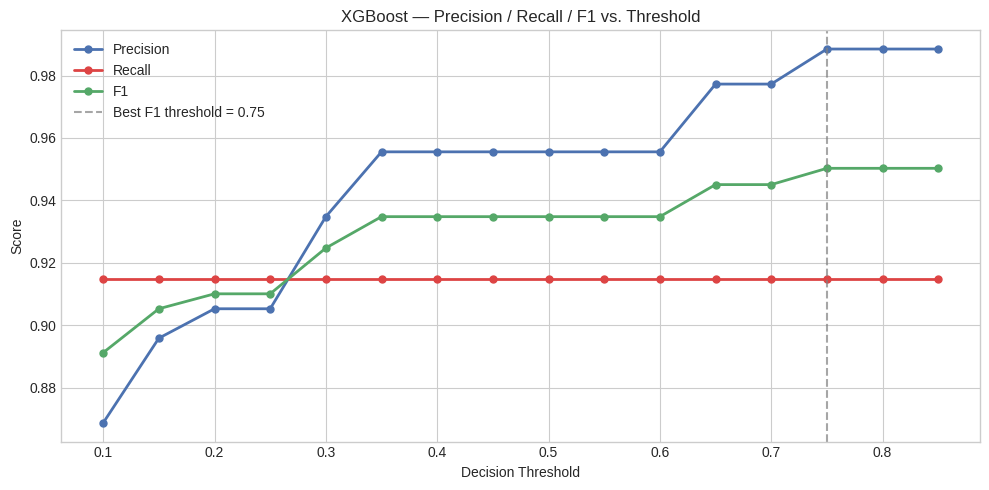


Best threshold by F1 : 0.75
 threshold  precision   recall       f1
      0.75   0.988506 0.914894 0.950276


In [20]:
from sklearn.metrics import f1_score, precision_score, recall_score

thresholds = np.arange(0.1, 0.9, 0.05)
rows = []
for t in thresholds:
    preds = (xgb_proba >= t).astype(int)
    rows.append({
        'threshold' : round(t, 2),
        'precision' : precision_score(y_test, preds, zero_division=0),
        'recall'    : recall_score(y_test, preds),
        'f1'        : f1_score(y_test, preds)
    })

thresh_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 5))
for col, color in [('precision','#4C72B0'),('recall','#DD4444'),('f1','#55A868')]:
    ax.plot(thresh_df['threshold'], thresh_df[col], label=col.capitalize(),
            color=color, lw=2, marker='o', markersize=5)

best_row = thresh_df.loc[thresh_df['f1'].idxmax()]
ax.axvline(best_row['threshold'], color='gray', linestyle='--', alpha=0.7,
           label=f"Best F1 threshold = {best_row['threshold']}")
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Score')
ax.set_title('XGBoost — Precision / Recall / F1 vs. Threshold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nBest threshold by F1 : {best_row['threshold']}")
print(thresh_df[thresh_df['threshold'] == best_row['threshold']].to_string(index=False))


  XGBoost (tuned threshold)
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00    163604
       Fraud       0.99      0.91      0.95        94

    accuracy                           1.00    163698
   macro avg       0.99      0.96      0.98    163698
weighted avg       1.00      1.00      1.00    163698

ROC-AUC  : 0.9677
PR-AUC   : 0.9186


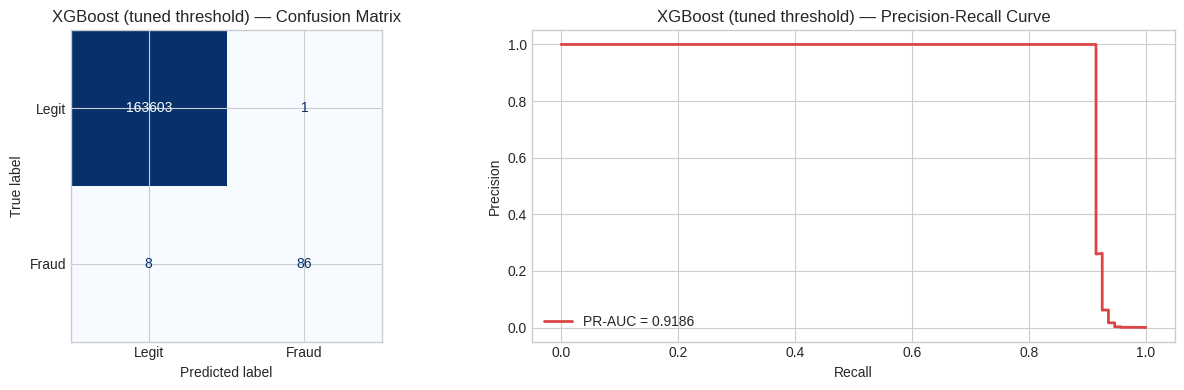

In [21]:
# ── Final evaluation at best threshold ───────────────────────────────
best_t = best_row['threshold']
_ = evaluate('XGBoost (tuned threshold)', xgb, X_test, y_test, threshold=best_t)

In [22]:
def predict_fraud(model, raw_transactions: pd.DataFrame,
                  threshold=0.5) -> pd.DataFrame:
    """
    Pass a DataFrame with the same raw columns as the original dataset.
    Returns the DataFrame with two extra columns:
      - fraud_score   : model probability of fraud (0-1)
      - fraud_flag    : 1 if score >= threshold, else 0
    """
    df_proc = engineer_features(raw_transactions)
    scores  = model.predict_proba(df_proc[FEATURE_COLS])[:, 1]
    out = raw_transactions.copy()
    out['fraud_score'] = scores
    out['fraud_flag']  = (scores >= threshold).astype(int)
    return out


# Quick demo: grab a few real examples from the test set
sample_idx  = X_test.sample(5, random_state=1).index
sample_raw  = df.loc[sample_idx, [c for c in df.columns
                                   if c not in ['isFraud'] + FEATURE_COLS +
                                               ['type_enc','errorOrig','errorDest',
                                                'orig_zero_after','dest_zero_before',
                                                'amount_ratio_orig','is_high_risk_type',
                                                'dest_balance_unchanged']]].copy()

# Restore original columns needed for feature engineering
original_cols = ['step','type','amount','nameOrig','oldbalanceOrg',
                 'newbalanceOrig','nameDest','oldbalanceDest',
                 'newbalanceDest','isFlaggedFraud']
sample_raw = df.loc[sample_idx, original_cols].copy()

result = predict_fraud(xgb, sample_raw, threshold=best_t)
print('Actual labels:', df.loc[sample_idx, 'isFraud'].values)
result[['step','type','amount','fraud_score','fraud_flag']]

Actual labels: [0. 0. 0. 0. 0.]


,step,type,amount,fraud_score,fraud_flag
369937,17,PAYMENT,5735.04,2.541626e-07,0
576221,26,CASH_IN,34981.64,2.012902e-07,0
796477,40,CASH_OUT,358191.28,2.053592e-07,0
480712,19,CASH_IN,335769.84,2.589467e-08,0
184624,13,CASH_OUT,127770.00,4.035138e-07,0


        MODEL EVALUATION — XGBoost
  Accuracy  : 0.9999
  Precision : 0.9885
  Recall    : 0.9149
  F1 Score  : 0.9503

  True  Negatives (correct legit)  : 163,603
  False Positives (false alarms)   : 1
  False Negatives (missed fraud)   : 8
  True  Positives (caught fraud)   : 86


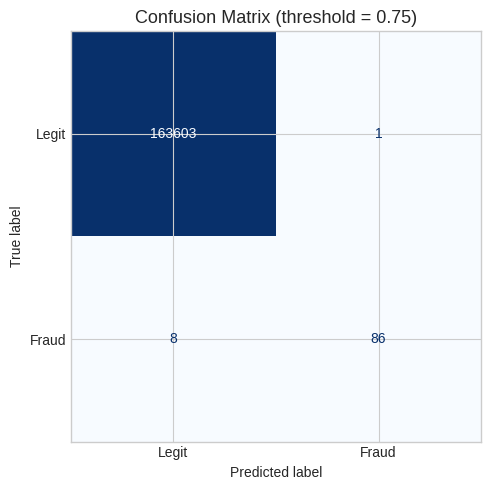

In [ ]:
# Full Evaluation Block 
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use your best threshold from the tuning step (or 0.5 as default)
THRESHOLD = best_t  

preds = (xgb_proba >= THRESHOLD).astype(int)

#  Metrics 
print("=" * 45)
print("        MODEL EVALUATION — XGBoost")
print("=" * 45)
print(f"  Accuracy  : {accuracy_score(y_test, preds):.4f}")
print(f"  Precision : {precision_score(y_test, preds):.4f}")
print(f"  Recall    : {recall_score(y_test, preds):.4f}")
print(f"  F1 Score  : {f1_score(y_test, preds):.4f}")
print("=" * 45)

# ── Confusion Matrix ──────────────────────────────────────────────────
cm = confusion_matrix(y_test, preds)
tn, fp, fn, tp = cm.ravel()

print(f"\n  True  Negatives (correct legit)  : {tn:,}")
print(f"  False Positives (false alarms)   : {fp:,}")
print(f"  False Negatives (missed fraud)   : {fn:,}")
print(f"  True  Positives (caught fraud)   : {tp:,}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Legit', 'Fraud']).plot(
    ax=ax, colorbar=False, cmap='Blues'
)
ax.set_title(f'Confusion Matrix (threshold = {THRESHOLD})', fontsize=13)
plt.tight_layout()
plt.show()